# VisDrone evaluation v2: K1 vs YOLOE, with SAHI fixed and measured

**What changed from v1, and why**

1. **SAHI was silently changing its own settings.** SAHI's `get_sliced_prediction` has a rule: if the
   confidence threshold is below 0.1, it *switches* the merge from GREEDYNMM/IOS to plain NMS/IOU and only
   logs a warning. v1 used `conf=0.01` and set SAHI's logger to ERROR, so the warning never showed. The
   "sahi_512" row in v1 was therefore NMS/IOU 0.5, not the GREEDYNMM/IOS it asked for.
2. **SAHI's full-image pass ran at 1024, not 1536.** SAHI uses one `image_size` for the slices and the
   full-image pass. So "SAHI" = 2x-zoomed slices + a *weaker* full pass (0.561) than our best full-image
   setting (0.625).
3. **Settings differed between notebooks** (slice resolution, confidence, overlap, merge), which is why
   SAHI numbers kept moving.

**How v2 works.** One inference engine for every model. It uses SAHI's own slicer (`get_slice_bboxes`)
and SAHI's own merge functions (`batched_nms`, `batched_greedy_nmm`), but calls them directly with every
setting explicit, so nothing can switch silently. Raw detections from each pass are cached, so merge
settings can be compared in seconds without re-running the GPU. A sanity cell checks the engine against
the SAHI library itself.

**Experiments (all on val; test-dev only for finalists, once)**
- **Z** – does zooming help? Slices at 1x / 1.5x / 2x / 2.5x zoom, AP split by object size.
- **M** – merge settings: which full-image pass to add, NMS vs GREEDYNMM, and a boundary filter that drops
  half-objects cut by an interior slice edge.
- **Y** – E2 (fine-tuned YOLOE-26m) and optionally E1 through the identical pipeline.
- **X** – K1 + E2 ensemble.
- **T** – test-dev for the finalists.

**Run with:** Save Version → Save & Run All, GPU T4×2, Internet ON.
Inputs to attach: the **visdrone-training** output (K1) and the **E2 notebook** output (`yoloe26m_e2_full.pt`).
Optional: the E1 notebook output. Total runtime ≈ 1.5–2 h.

In [1]:
# --- Setup ---------------------------------------------------------------
!pip install -q "ultralytics==8.4.174" "sahi==0.12.8" pycocotools ensemble-boxes "git+https://github.com/ultralytics/CLIP.git"
import os, io, json, time, pickle, logging, contextlib, platform
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import ultralytics, sahi
from ultralytics import YOLO
from ultralytics.utils import LOGGER
LOGGER.setLevel(logging.ERROR)                  # hides the 'half is deprecated' flood
logging.getLogger("sahi").setLevel(logging.WARNING)

ROOT = Path("/kaggle/working") if Path("/kaggle").exists() else Path.cwd()
DATA = Path("/tmp/VisDrone") if Path("/kaggle").exists() else ROOT / "VisDrone"
EVAL = ROOT / "eval_v2"; CACHE = EVAL / "cache"
for d in (DATA, EVAL, CACHE): d.mkdir(parents=True, exist_ok=True)

CUDA = torch.cuda.is_available()
DEV = 0 if CUDA else "cpu"
HALF = CUDA
print("Python", platform.python_version(), "| torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| sahi", sahi.__version__, "| GPUs", torch.cuda.device_count())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python 3.13.15 | torch 2.11.0+cu128 | ultralytics 8.4.174 | sahi 0.12.8 | GPUs 2


In [2]:
# --- Config ----------------------------------------------------------------
INPUT_ROOT = Path("/kaggle/input")
def find(pattern):
    hits = sorted(INPUT_ROOT.rglob(pattern))
    return hits[0] if hits else None

MODELS = {                                        # tag -> weights; None = skipped
    "K1": find("K1_y26m_tiles/weights/best.pt"),
    "E2": find("yoloe26m_e2_full.pt"),            # 'yoloe' in the filename -> loads as YOLOE
    "E1": find("yoloe26m_e1_linprobe.pt"),        # optional
}
for k, v in MODELS.items(): print(f"{k}: {v}")
assert MODELS["K1"], "Attach the visdrone-training notebook output (K1)"

CONF = 0.01          # same as v1 and the paper (Sec. IV-D)
MAX_DET = 1000       # per forward pass; scoring caps at 500/image like VisDrone
OVERLAP = 0.25       # slice overlap, same as v1
SLICE_BATCH = 16     # slices per forward pass
N_VAL = None         # e.g. 60 for a quick dry run; None = all 548
RUN_E1 = MODELS["E1"] is not None
RUN_TESTDEV = True

# Pass keys: "full@S" = whole image at imgsz S;  "sT@S" = T×T slices, each resized to S (zoom = S/T)
ZOOM_PASSES = ["s512@512", "s512@768", "s512@1024", "s512@1280", "s640@1024", "s384@768"]
FULL_PASSES = ["full@1024", "full@1536"]

K1: /kaggle/input/notebooks/ciiphersiren/visdrone-training/runs/K1_y26m_tiles/weights/best.pt
E2: /kaggle/input/notebooks/ciiphersiren/notebook9e93051a5d/yoloe26m_e2_full.pt
E1: /kaggle/input/notebooks/ciiphersiren/notebook4fa48171b6/yoloe26m_e1_linprobe.pt


In [3]:
# --- Data: VisDrone val + test-dev (images + original annotations) ---------
import zipfile, urllib.request
BASE = "https://github.com/ultralytics/assets/releases/download/v0.0.0/"
SPLIT_DIRS = {"val": DATA / "VisDrone2019-DET-val", "test-dev": DATA / "VisDrone2019-DET-test-dev"}
for split, d in SPLIT_DIRS.items():
    if not d.exists():
        z = DATA / f"{d.name}.zip"
        print("Downloading", d.name)
        urllib.request.urlretrieve(BASE + z.name, z)
        with zipfile.ZipFile(z) as f: f.extractall(DATA)
        z.unlink()
    print(split, len(list((d / "images").glob("*.jpg"))), "images")

val 548 images
test-dev 1610 images


In [4]:
# --- Ground truth + scorer (v1's GT rules, plus AP by object size) ---------
from PIL import Image as PILImage
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
NAMES = ["pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle", "awning-tricycle", "bus", "motor"]

def build_gt(split_dir):
    # identical to v1: ignored regions (score==0 or cat==0) become 'crowd' boxes for every class,
    # so detections inside them are neither TP nor FP; 'others' (11) dropped.
    images, anns, aid = [], [], 1
    for i, ann in enumerate(sorted((split_dir / "annotations").glob("*.txt"))):
        W_, H_ = PILImage.open(split_dir / "images" / f"{ann.stem}.jpg").size
        images.append(dict(id=i, file_name=f"{ann.stem}.jpg", width=W_, height=H_))
        for row in ann.read_text().strip().splitlines():
            v = row.strip().rstrip(",").split(",")
            if len(v) < 6: continue
            x, y, w, h, score, cat = map(int, v[:6])
            if w <= 0 or h <= 0 or cat == 11: continue
            if score == 0 or cat == 0:
                for c in range(1, 11):
                    anns.append(dict(id=aid, image_id=i, category_id=c, bbox=[x, y, w, h], area=w * h, iscrowd=1)); aid += 1
            else:
                anns.append(dict(id=aid, image_id=i, category_id=cat, bbox=[x, y, w, h], area=w * h, iscrowd=0)); aid += 1
    return dict(images=images, annotations=anns, categories=[dict(id=i + 1, name=n) for i, n in enumerate(NAMES)])

GT, GTC = {}, {}
for split, d in SPLIT_DIRS.items():
    GT[split] = build_gt(d)
    with contextlib.redirect_stdout(io.StringIO()):
        GTC[split] = COCO(); GTC[split].dataset = GT[split]; GTC[split].createIndex()
    print(split, len(GT[split]["images"]), "images,", sum(a["iscrowd"] == 0 for a in GT[split]["annotations"]), "objects")

def image_list(split):
    ims = GT[split]["images"]
    return ims[:N_VAL] if (split == "val" and N_VAL) else ims

# Size buckets (paper Sec. IV-D): tiny < 16², small 16²–32², plus COCO 'small' (< 32²) and medium+ (≥ 32²)
AREAS = {"all": [0, 1e10], "tiny": [0, 16**2], "small": [16**2, 32**2], "coco_small": [0, 32**2], "medium+": [32**2, 1e10]}

def coco_eval(split, dets):
    # dets: dict image_id -> (N,6) [x1,y1,x2,y2,score,cls0..9]
    ids = [im["id"] for im in image_list(split)]
    rows = [np.c_[np.full(len(d), i), d[:, 0], d[:, 1], d[:, 2] - d[:, 0], d[:, 3] - d[:, 1], d[:, 4], d[:, 5] + 1]
            for i, d in dets.items() if len(d)]
    if not rows: return {"AP": 0.0, "AP50": 0.0}, {}
    with contextlib.redirect_stdout(io.StringIO()):
        dt = GTC[split].loadRes(np.concatenate(rows).astype(np.float64))
        E = COCOeval(GTC[split], dt, "bbox")
        E.params.imgIds = ids
        E.params.maxDets = [1, 100, 500]
        E.params.areaRng = list(AREAS.values()); E.params.areaRngLbl = list(AREAS.keys())
        E.evaluate(); E.accumulate()
    P = E.eval["precision"]                       # [IoU, recall, class, area, maxDets]
    def ap(p): p = p[p > -1]; return float(p.mean()) if p.size else float("nan")
    m = {"AP": ap(P[:, :, :, 0, -1]), "AP50": ap(P[0, :, :, 0, -1]), "AP75": ap(P[5, :, :, 0, -1])}
    for a, lbl in enumerate(AREAS):
        if lbl != "all":
            m[f"AP_{lbl}"] = ap(P[:, :, :, a, -1]); m[f"AP50_{lbl}"] = ap(P[0, :, :, a, -1])
    per_cls = {NAMES[k]: ap(P[0, :, k, 0, -1]) for k in range(len(NAMES))}
    return m, per_cls

val 548 images, 38759 objects
test-dev 1610 images, 75102 objects


In [5]:
# --- Inference engine: SAHI's slicer, explicit settings, cached raw detections ---
from sahi.slicing import get_slice_bboxes

_loaded = {}
def model(tag):
    if tag not in _loaded:
        _loaded[tag] = YOLO(str(MODELS[tag]))
        _loaded[tag].predict(np.zeros((640, 640, 3), np.uint8), imgsz=640, half=HALF, device=DEV, verbose=False)  # warm-up
    return _loaded[tag]

def _arr(r):
    b = r.boxes
    if b is None or len(b) == 0: return np.zeros((0, 6), np.float32)
    return np.c_[b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()].astype(np.float32)

def parse_pass(key):
    kind, sz = key.split("@")
    return ("full", None, int(sz)) if kind == "full" else ("slice", int(kind[1:]), int(sz))

def run_pass_on_image(m, img, key):
    kind, T, S = parse_pass(key)
    if kind == "full":
        r = m.predict(img, imgsz=S, conf=CONF, max_det=MAX_DET, half=HALF, device=DEV, verbose=False)[0]
        return _arr(r), None
    H, W = img.shape[:2]
    boxes = get_slice_bboxes(image_height=H, image_width=W, slice_height=T, slice_width=T,
                             auto_slice_resolution=False, overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP)
    crops = [np.ascontiguousarray(img[y1:y2, x1:x2]) for x1, y1, x2, y2 in boxes]
    D, SB = [], []
    for i in range(0, len(crops), SLICE_BATCH):
        rs = m.predict(crops[i:i + SLICE_BATCH], imgsz=S, conf=CONF, max_det=MAX_DET, half=HALF, device=DEV, verbose=False)
        for r, (x1, y1, x2, y2) in zip(rs, boxes[i:i + SLICE_BATCH]):
            a = _arr(r); a[:, [0, 2]] += x1; a[:, [1, 3]] += y1
            D.append(a); SB.append(np.tile(np.float32([x1, y1, x2, y2]), (len(a), 1)))
    return np.concatenate(D), np.concatenate(SB)

def run_pass(tag, split, key):
    # Raw (un-merged) detections for every image, cached to disk. Returns (dict, seconds per image).
    f = CACHE / f"{tag}_{split}_{key}_{N_VAL or 'all'}.pkl"
    if f.exists():
        return pickle.load(open(f, "rb"))
    m = model(tag); out = {}; t = 0.0
    for im in image_list(split):
        img = cv2.imread(str(SPLIT_DIRS[split] / "images" / im["file_name"]))
        if CUDA: torch.cuda.synchronize()
        t0 = time.perf_counter()
        out[im["id"]] = run_pass_on_image(m, img, key)
        if CUDA: torch.cuda.synchronize()
        t += time.perf_counter() - t0
    res = (out, t / len(out))
    pickle.dump(res, open(f, "wb"))
    print(f"  pass {tag} {split} {key}: {res[1]*1000:.0f} ms/img")
    return res

In [6]:
# --- Merging: SAHI's own NMS / GREEDYNMM, called directly (no silent switching) ---
from sahi.postprocess.combine import batched_nms, batched_greedy_nmm
from ensemble_boxes import weighted_boxes_fusion

def _overlap(a, b, metric):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    aa = (a[2] - a[0]) * (a[3] - a[1]); ab = (b[2] - b[0]) * (b[3] - b[1])
    den = min(aa, ab) if metric == "IOS" else (aa + ab - inter)
    return inter / den if den > 0 else 0.0

def edge_filter(d, sb, W, H, margin=2.0):
    # Drop slice detections that touch an *interior* slice edge (a cut object). With 25% overlap the
    # neighbouring slice sees small objects whole, and the full-image pass covers big ones.
    if sb is None or len(d) == 0: return d
    x1, y1, x2, y2 = d[:, 0], d[:, 1], d[:, 2], d[:, 3]
    sx1, sy1, sx2, sy2 = sb[:, 0], sb[:, 1], sb[:, 2], sb[:, 3]
    cut = (((sx1 > 0) & (x1 <= sx1 + margin)) | ((sy1 > 0) & (y1 <= sy1 + margin)) |
           ((sx2 < W) & (x2 >= sx2 - margin)) | ((sy2 < H) & (y2 >= sy2 - margin)))
    return d[~cut]

def merge(parts, method="NMS", metric="IOU", thr=0.5):
    P = np.concatenate([p for p in parts if len(p)]) if any(len(p) for p in parts) else np.zeros((0, 6), np.float32)
    if len(P) == 0: return P
    if method == "NMS":
        return P[batched_nms(P, match_metric=metric, match_threshold=thr)]
    if method == "GREEDYNMM":                     # same logic as SAHI's _apply_merge: union box, max score
        out = []
        for keep, mlist in batched_greedy_nmm(P, match_metric=metric, match_threshold=thr).items():
            b = P[keep].copy()
            for j in mlist:
                if _overlap(b, P[j], metric) >= thr:
                    b[0], b[1] = min(b[0], P[j, 0]), min(b[1], P[j, 1])
                    b[2], b[3] = max(b[2], P[j, 2]), max(b[3], P[j, 3]); b[4] = max(b[4], P[j, 4])
            out.append(b)
        return np.array(out, np.float32).reshape(-1, 6)
    raise ValueError(method)

def wbf(parts_per_model, W, H, thr=0.55):
    # Weighted box fusion across models (each model's parts merged first)
    bl, sl, ll = [], [], []
    for d in parts_per_model:
        bl.append(np.clip(d[:, :4] / [W, H, W, H], 0, 1).tolist()); sl.append(d[:, 4].tolist()); ll.append(d[:, 5].tolist())
    b, s, l = weighted_boxes_fusion(bl, sl, ll, iou_thr=thr, skip_box_thr=CONF)
    return np.c_[np.asarray(b) * [W, H, W, H], s, l].astype(np.float32).reshape(-1, 6)

RESULTS, PER_CLASS = [], {}
WH = {s: {im["id"]: (im["width"], im["height"]) for im in GT[s]["images"]} for s in GT}

def evaluate(name, tag, split, passes, method="NMS", metric="IOU", thr=0.5, edge=False, record=True):
    # passes: list of pass keys combined for one model, e.g. ["s512@1024", "full@1536"]
    runs = [run_pass(tag, split, k) for k in passes]
    dets, t0 = {}, time.perf_counter()
    for im in image_list(split):
        i = im["id"]; W, H = WH[split][i]; parts = []
        for (out, _), k in zip(runs, passes):
            d, sb = out[i]
            parts.append(edge_filter(d, sb, W, H) if edge else d)
        dets[i] = merge(parts, method, metric, thr) if len(passes) > 1 or parse_pass(passes[0])[0] == "slice" else parts[0]
    merge_s = (time.perf_counter() - t0) / len(dets)
    m, pc = coco_eval(split, dets)
    row = dict(name=name, model=tag, split=split, passes="+".join(passes),
               merge=f"{method}-{metric}-{thr}" + ("+edge" if edge else ""),
               ms_per_img=round(1000 * (sum(r[1] for r in runs) + merge_s)), **{k: round(v, 4) for k, v in m.items()})
    if record:
        RESULTS.append(row); PER_CLASS[(name, split)] = pc
    print(f"{name:52s} AP50={m['AP50']:.4f} AP={m['AP']:.4f} AP_tiny={m['AP_tiny']:.4f}  {row['ms_per_img']} ms")
    return row, dets

In [7]:
# --- Sanity check: our engine vs the SAHI library on 25 val images --------
# Runs SAHI exactly as v1 did, and our engine with the settings SAHI *actually* used after its silent switch.
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
_nv = N_VAL; N_VAL = 25
sm = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(MODELS["K1"]),
                                        confidence_threshold=CONF, device="cuda:0" if CUDA else "cpu", image_size=1024)
sm.model.overrides["max_det"] = MAX_DET
lib = {}
for im in image_list("val"):
    r = get_sliced_prediction(str(SPLIT_DIRS["val"] / "images" / im["file_name"]), sm, slice_height=512, slice_width=512,
                              overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP, perform_standard_pred=True,
                              postprocess_type="GREEDYNMM", postprocess_match_metric="IOS", postprocess_match_threshold=0.5, verbose=0)
    lib[im["id"]] = np.array([[*p.bbox.to_xyxy(), p.score.value, p.category.id] for p in r.object_prediction_list], np.float32).reshape(-1, 6)
os.environ.pop("CUDA_VISIBLE_DEVICES", None)      # SAHI sets this; undo it
m_lib, _ = coco_eval("val", lib)
r_eng, _ = evaluate("engine: s512@1024+full@1024 NMS-IOU-0.5 (=what SAHI ran)", "K1", "val", ["s512@1024", "full@1024"],
                    "NMS", "IOU", 0.5, record=False)
print(f"\nSAHI library: AP50={m_lib['AP50']:.4f} AP={m_lib['AP']:.4f}   |   engine: AP50={r_eng['AP50']:.4f} AP={r_eng['AP']:.4f}")
print("Should agree within ~0.005. (Tiny differences: PIL vs OpenCV JPEG decoding.)")
for f in CACHE.glob("*_25.pkl"): f.unlink()       # don't reuse the 25-image cache
N_VAL = _nv
del sm; torch.cuda.empty_cache()

2026-10-13 15:22:48,744 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:22:57,199 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:22:58,184 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:22:59,153 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:23:00,145 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:23:01,132 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.01). (predict.py:327)
2026-10-13 15:23:02,112 - sahi - WARNING - Switching postprocess type/metric to NM

  pass K1 val s512@1024: 543 ms/img
  pass K1 val full@1024: 110 ms/img
engine: s512@1024+full@1024 NMS-IOU-0.5 (=what SAHI ran) AP50=0.6754 AP=0.4852 AP_tiny=0.1339  657 ms

SAHI library: AP50=0.6760 AP=0.4748   |   engine: AP50=0.6754 AP=0.4852
Should agree within ~0.005. (Tiny differences: PIL vs OpenCV JPEG decoding.)


## Z — Does zooming help?

Each row is **slices only** (no full-image pass) so the effect of zoom is isolated. Zoom = slice resize ÷ slice size.
Watch `AP_tiny` and `AP_small` (where zoom should help) and `AP_medium+` (big objects get cut by slices, so slices
alone lose them; that's what the full-image pass is for). Full-image rows are the reference.

In [8]:
for k in FULL_PASSES:
    evaluate(f"K1 {k}", "K1", "val", [k])
for k in ZOOM_PASSES:
    T, S = parse_pass(k)[1:]
    evaluate(f"K1 slices only {k} (zoom {S/T:.2f}x)", "K1", "val", [k], "NMS", "IOU", 0.5)

cols = ["name", "AP50", "AP", "AP50_tiny", "AP50_small", "AP50_medium+", "ms_per_img"]
pd.DataFrame(RESULTS)[cols]

  pass K1 val full@1024: 15 ms/img
K1 full@1024                                         AP50=0.5606 AP=0.3520 AP_tiny=0.1396  15 ms
  pass K1 val full@1536: 38 ms/img
K1 full@1536                                         AP50=0.6242 AP=0.3983 AP_tiny=0.1953  38 ms
  pass K1 val s512@512: 62 ms/img
K1 slices only s512@512 (zoom 1.00x)                 AP50=0.5703 AP=0.3493 AP_tiny=0.1634  66 ms
  pass K1 val s512@768: 145 ms/img
K1 slices only s512@768 (zoom 1.50x)                 AP50=0.6238 AP=0.3846 AP_tiny=0.2049  149 ms
  pass K1 val s512@1024: 236 ms/img
K1 slices only s512@1024 (zoom 2.00x)                AP50=0.6277 AP=0.3878 AP_tiny=0.2250  240 ms
  pass K1 val s512@1280: 384 ms/img
K1 slices only s512@1280 (zoom 2.50x)                AP50=0.6246 AP=0.3807 AP_tiny=0.2305  388 ms
  pass K1 val s640@1024: 153 ms/img
K1 slices only s640@1024 (zoom 1.60x)                AP50=0.6298 AP=0.3911 AP_tiny=0.2120  157 ms
  pass K1 val s384@768: 237 ms/img
K1 slices only s384@768 (zoom 2.00x

,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img
0,K1 full@1024,0.5606,0.3520,0.3265,0.5644,0.7065,15
1,K1 full@1536,0.6242,0.3983,0.4288,0.6328,0.7340,38
2,K1 slices only s512@512 (zoom 1.00x),0.5703,0.3493,0.3689,0.5829,0.6931,66
3,K1 slices only s512@768 (zoom 1.50x),0.6238,0.3846,0.4520,0.6342,0.7246,149
4,K1 slices only s512@1024 (zoom 2.00x),0.6277,0.3878,0.4803,0.6374,0.7187,240
5,K1 slices only s512@1280 (zoom 2.50x),0.6246,0.3807,0.4936,0.6322,0.7078,388
6,K1 slices only s640@1024 (zoom 1.60x),0.6298,0.3911,0.4622,0.6383,0.7286,157
7,K1 slices only s384@768 (zoom 2.00x),0.6135,0.3739,0.4649,0.6240,0.7082,241


## M — Merge settings

Same cached detections, different ways of combining them. Rows:
- **v1 reference**: 2x slices + full@1024, NMS-IOU 0.5. That's what v1's `sahi_512` really ran; should land near 0.636.
- **+ full@1536**: the stronger full-image pass instead of 1024.
- **GREEDYNMM-IOS**: what v1 *asked for* (merges a cut half-object into the whole one, but can also fuse neighbours in crowds).
- **+edge**: boundary filter, then NMS.

In [9]:
SLICE_CANDIDATES = ["s512@1024", "s512@1280", "s640@1024"]
MERGES = [("NMS", "IOU", 0.5, False), ("NMS", "IOU", 0.6, False), ("NMS", "IOU", 0.7, False),
          ("GREEDYNMM", "IOS", 0.5, False), ("NMS", "IOU", 0.6, True), ("NMS", "IOU", 0.7, True)]

evaluate("K1 v1 reference: s512@1024+full@1024 NMS-IOU-0.5", "K1", "val", ["s512@1024", "full@1024"], "NMS", "IOU", 0.5)
for sk in SLICE_CANDIDATES:
    for meth, met, thr, edge in MERGES:
        evaluate(f"K1 {sk}+full@1536 {meth}-{met}-{thr}{'+edge' if edge else ''}", "K1", "val",
                 [sk, "full@1536"], meth, met, thr, edge)

df = pd.DataFrame(RESULTS)
k1_sahi = df[(df.model == "K1") & df.passes.str.contains("full@1536") & df.passes.str.startswith("s")]
BEST = k1_sahi.sort_values(["AP50", "AP"], ascending=False).iloc[0]
BEST_PASSES, BEST_MERGE = BEST.passes.split("+"), BEST.merge
_m = BEST_MERGE.split("+")[0].split("-"); BEST_ARGS = (_m[0], _m[1], float(_m[2]), BEST_MERGE.endswith("+edge"))
print("\nBest K1 SAHI config on val:", BEST.passes, BEST.merge, f"AP50={BEST.AP50} AP={BEST.AP}")
df[df.model == "K1"].sort_values("AP50", ascending=False)[cols + ["merge"]].head(12)

K1 v1 reference: s512@1024+full@1024 NMS-IOU-0.5     AP50=0.6362 AP=0.3981 AP_tiny=0.2238  256 ms
K1 s512@1024+full@1536 NMS-IOU-0.5                   AP50=0.6411 AP=0.4012 AP_tiny=0.2265  278 ms
K1 s512@1024+full@1536 NMS-IOU-0.6                   AP50=0.6325 AP=0.3981 AP_tiny=0.2263  278 ms
K1 s512@1024+full@1536 NMS-IOU-0.7                   AP50=0.6178 AP=0.3929 AP_tiny=0.2267  278 ms
K1 s512@1024+full@1536 GREEDYNMM-IOS-0.5             AP50=0.5552 AP=0.3174 AP_tiny=0.1711  286 ms
K1 s512@1024+full@1536 NMS-IOU-0.6+edge              AP50=0.6644 AP=0.4254 AP_tiny=0.2356  278 ms
K1 s512@1024+full@1536 NMS-IOU-0.7+edge              AP50=0.6624 AP=0.4273 AP_tiny=0.2367  278 ms
K1 s512@1280+full@1536 NMS-IOU-0.5                   AP50=0.6434 AP=0.4015 AP_tiny=0.2332  426 ms
K1 s512@1280+full@1536 NMS-IOU-0.6                   AP50=0.6366 AP=0.3998 AP_tiny=0.2332  427 ms
K1 s512@1280+full@1536 NMS-IOU-0.7                   AP50=0.6213 AP=0.3945 AP_tiny=0.2329  427 ms
K1 s512@1280+full@15

,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img,merge
19,K1 s512@1280+full@1536 NMS-IOU-0.6+edge,0.6669,0.4251,0.5226,0.6748,0.7532,426,NMS-IOU-0.6+edge
13,K1 s512@1024+full@1536 NMS-IOU-0.6+edge,0.6644,0.4254,0.5026,0.6759,0.7537,278,NMS-IOU-0.6+edge
20,K1 s512@1280+full@1536 NMS-IOU-0.7+edge,0.6631,0.4267,0.5179,0.6713,0.7503,427,NMS-IOU-0.7+edge
14,K1 s512@1024+full@1536 NMS-IOU-0.7+edge,0.6624,0.4273,0.4997,0.6734,0.7530,278,NMS-IOU-0.7+edge
25,K1 s640@1024+full@1536 NMS-IOU-0.6+edge,0.6546,0.4186,0.4791,0.6646,0.7513,196,NMS-IOU-0.6+edge
26,K1 s640@1024+full@1536 NMS-IOU-0.7+edge,0.6518,0.4201,0.4747,0.6620,0.7497,196,NMS-IOU-0.7+edge
15,K1 s512@1280+full@1536 NMS-IOU-0.5,0.6434,0.4015,0.5032,0.6490,0.7357,426,NMS-IOU-0.5
9,K1 s512@1024+full@1536 NMS-IOU-0.5,0.6411,0.4012,0.4882,0.6494,0.7358,278,NMS-IOU-0.5
16,K1 s512@1280+full@1536 NMS-IOU-0.6,0.6366,0.3998,0.5006,0.6411,0.7287,427,NMS-IOU-0.6
8,K1 v1 reference: s512@1024+full@1024 NMS-IOU-0.5,0.6362,0.3981,0.4804,0.6443,0.7338,256,NMS-IOU-0.5


## Y — YOLOE through the identical pipeline

E2 = YOLOE-26m full fine-tune (closed-set, 10 classes). E1 = linear probe (optional). Same passes, same merge, same scorer as K1.

In [10]:
for tag in ["E2"] + (["E1"] if RUN_E1 else []):
    if MODELS[tag] is None: continue
    evaluate(f"{tag} full@1536", tag, "val", ["full@1536"])
    evaluate(f"{tag} v1 reference: s512@1024+full@1024 NMS-IOU-0.5", tag, "val", ["s512@1024", "full@1024"], "NMS", "IOU", 0.5)
    evaluate(f"{tag} best-K1-SAHI: {'+'.join(BEST_PASSES)} {BEST_MERGE}", tag, "val", BEST_PASSES, *BEST_ARGS)
pd.DataFrame(RESULTS)[cols + ["merge"]].tail(6)

  pass E2 val full@1536: 34 ms/img
E2 full@1536                                         AP50=0.6015 AP=0.3839 AP_tiny=0.1862  34 ms
  pass E2 val s512@1024: 230 ms/img
  pass E2 val full@1024: 17 ms/img
E2 v1 reference: s512@1024+full@1024 NMS-IOU-0.5     AP50=0.6184 AP=0.3843 AP_tiny=0.2138  250 ms
  pass E2 val s512@1280: 373 ms/img
E2 best-K1-SAHI: s512@1280+full@1536 NMS-IOU-0.6+edge AP50=0.6508 AP=0.4139 AP_tiny=0.2347  412 ms
  pass E1 val full@1536: 34 ms/img
E1 full@1536                                         AP50=0.3342 AP=0.1874 AP_tiny=0.0490  34 ms
  pass E1 val s512@1024: 230 ms/img
  pass E1 val full@1024: 16 ms/img
E1 v1 reference: s512@1024+full@1024 NMS-IOU-0.5     AP50=0.3746 AP=0.2035 AP_tiny=0.0599  251 ms
  pass E1 val s512@1280: 374 ms/img
E1 best-K1-SAHI: s512@1280+full@1536 NMS-IOU-0.6+edge AP50=0.3891 AP=0.2151 AP_tiny=0.0652  412 ms


,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img,merge
27,E2 full@1536,0.6015,0.3839,0.4094,0.6059,0.7176,34,NMS-IOU-0.5
28,E2 v1 reference: s512@1024+full@1024 NMS-IOU-0.5,0.6184,0.3843,0.4640,0.6289,0.7161,250,NMS-IOU-0.5
29,E2 best-K1-SAHI: s512@1280+full@1536 NMS-IOU-0...,0.6508,0.4139,0.4997,0.6587,0.7394,412,NMS-IOU-0.6+edge
30,E1 full@1536,0.3342,0.1874,0.1260,0.3128,0.5100,34,NMS-IOU-0.5
31,E1 v1 reference: s512@1024+full@1024 NMS-IOU-0.5,0.3746,0.2035,0.1581,0.3594,0.5405,251,NMS-IOU-0.5
32,E1 best-K1-SAHI: s512@1280+full@1536 NMS-IOU-0...,0.3891,0.2151,0.1726,0.3748,0.5515,412,NMS-IOU-0.6+edge


## X — K1 + E2 ensemble

Each model's detections are first merged with the best SAHI config, then the two models are fused.
WBF averages boxes found by both models; NMS just keeps the best one. Latency is the sum of both models.

In [11]:
def ensemble(name, split, passes, fuse="WBF", thr=0.55):
    per_model, ms = [], 0
    for tag in ["K1", "E2"]:
        r, d = evaluate(f"  (part) {tag} {'+'.join(passes)}", tag, split, passes, *BEST_ARGS, record=False)
        per_model.append(d); ms += r["ms_per_img"]
    dets = {}
    for im in image_list(split):
        i = im["id"]; W, H = WH[split][i]
        ds = [pm[i] for pm in per_model]
        dets[i] = wbf(ds, W, H, thr) if fuse == "WBF" else merge(ds, "NMS", "IOU", thr)
    m, pc = coco_eval(split, dets)
    row = dict(name=name, model="K1+E2", split=split, passes="+".join(passes), merge=f"{BEST_MERGE} then {fuse}-{thr}",
               ms_per_img=ms, **{k: round(v, 4) for k, v in m.items()})
    RESULTS.append(row); PER_CLASS[(name, split)] = pc
    print(f"{name:52s} AP50={m['AP50']:.4f} AP={m['AP']:.4f} AP_tiny={m['AP_tiny']:.4f}  ~{ms} ms")
    return row

if MODELS["E2"] is not None:
    ensemble("K1+E2 full@1536, WBF-0.55", "val", ["full@1536"], "WBF", 0.55)
    ensemble("K1+E2 best SAHI, WBF-0.55", "val", BEST_PASSES, "WBF", 0.55)
    ensemble("K1+E2 best SAHI, WBF-0.65", "val", BEST_PASSES, "WBF", 0.65)
    ensemble("K1+E2 best SAHI, NMS-0.6", "val", BEST_PASSES, "NMS", 0.6)
pd.DataFrame(RESULTS)[cols + ["merge"]].tail(4)

  (part) K1 full@1536                                AP50=0.6242 AP=0.3983 AP_tiny=0.1953  38 ms
  (part) E2 full@1536                                AP50=0.6015 AP=0.3839 AP_tiny=0.1862  34 ms
K1+E2 full@1536, WBF-0.55                            AP50=0.6334 AP=0.4022 AP_tiny=0.1985  ~72 ms
  (part) K1 s512@1280+full@1536                      AP50=0.6669 AP=0.4251 AP_tiny=0.2451  427 ms
  (part) E2 s512@1280+full@1536                      AP50=0.6508 AP=0.4139 AP_tiny=0.2347  412 ms
K1+E2 best SAHI, WBF-0.55                            AP50=0.6724 AP=0.4293 AP_tiny=0.2461  ~839 ms
  (part) K1 s512@1280+full@1536                      AP50=0.6669 AP=0.4251 AP_tiny=0.2451  427 ms
  (part) E2 s512@1280+full@1536                      AP50=0.6508 AP=0.4139 AP_tiny=0.2347  412 ms
K1+E2 best SAHI, WBF-0.65                            AP50=0.6825 AP=0.4383 AP_tiny=0.2543  ~839 ms
  (part) K1 s512@1280+full@1536                      AP50=0.6669 AP=0.4251 AP_tiny=0.2451  427 ms
  (part) E2 s512@128

,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img,merge
33,"K1+E2 full@1536, WBF-0.55",0.6334,0.4022,0.4384,0.6421,0.7432,72,NMS-IOU-0.6+edge then WBF-0.55
34,"K1+E2 best SAHI, WBF-0.55",0.6724,0.4293,0.5246,0.6790,0.7586,839,NMS-IOU-0.6+edge then WBF-0.55
35,"K1+E2 best SAHI, WBF-0.65",0.6825,0.4383,0.5383,0.6912,0.7663,839,NMS-IOU-0.6+edge then WBF-0.65
36,"K1+E2 best SAHI, NMS-0.6",0.6723,0.4298,0.5298,0.6802,0.7593,839,NMS-IOU-0.6+edge then NMS-0.6


## Visual check — densest val image

Left: K1 full@1536. Right: K1 best SAHI config. Boxes shown above confidence 0.3. The crop below zooms into the
busiest region so you can see what slicing adds (or merges away).

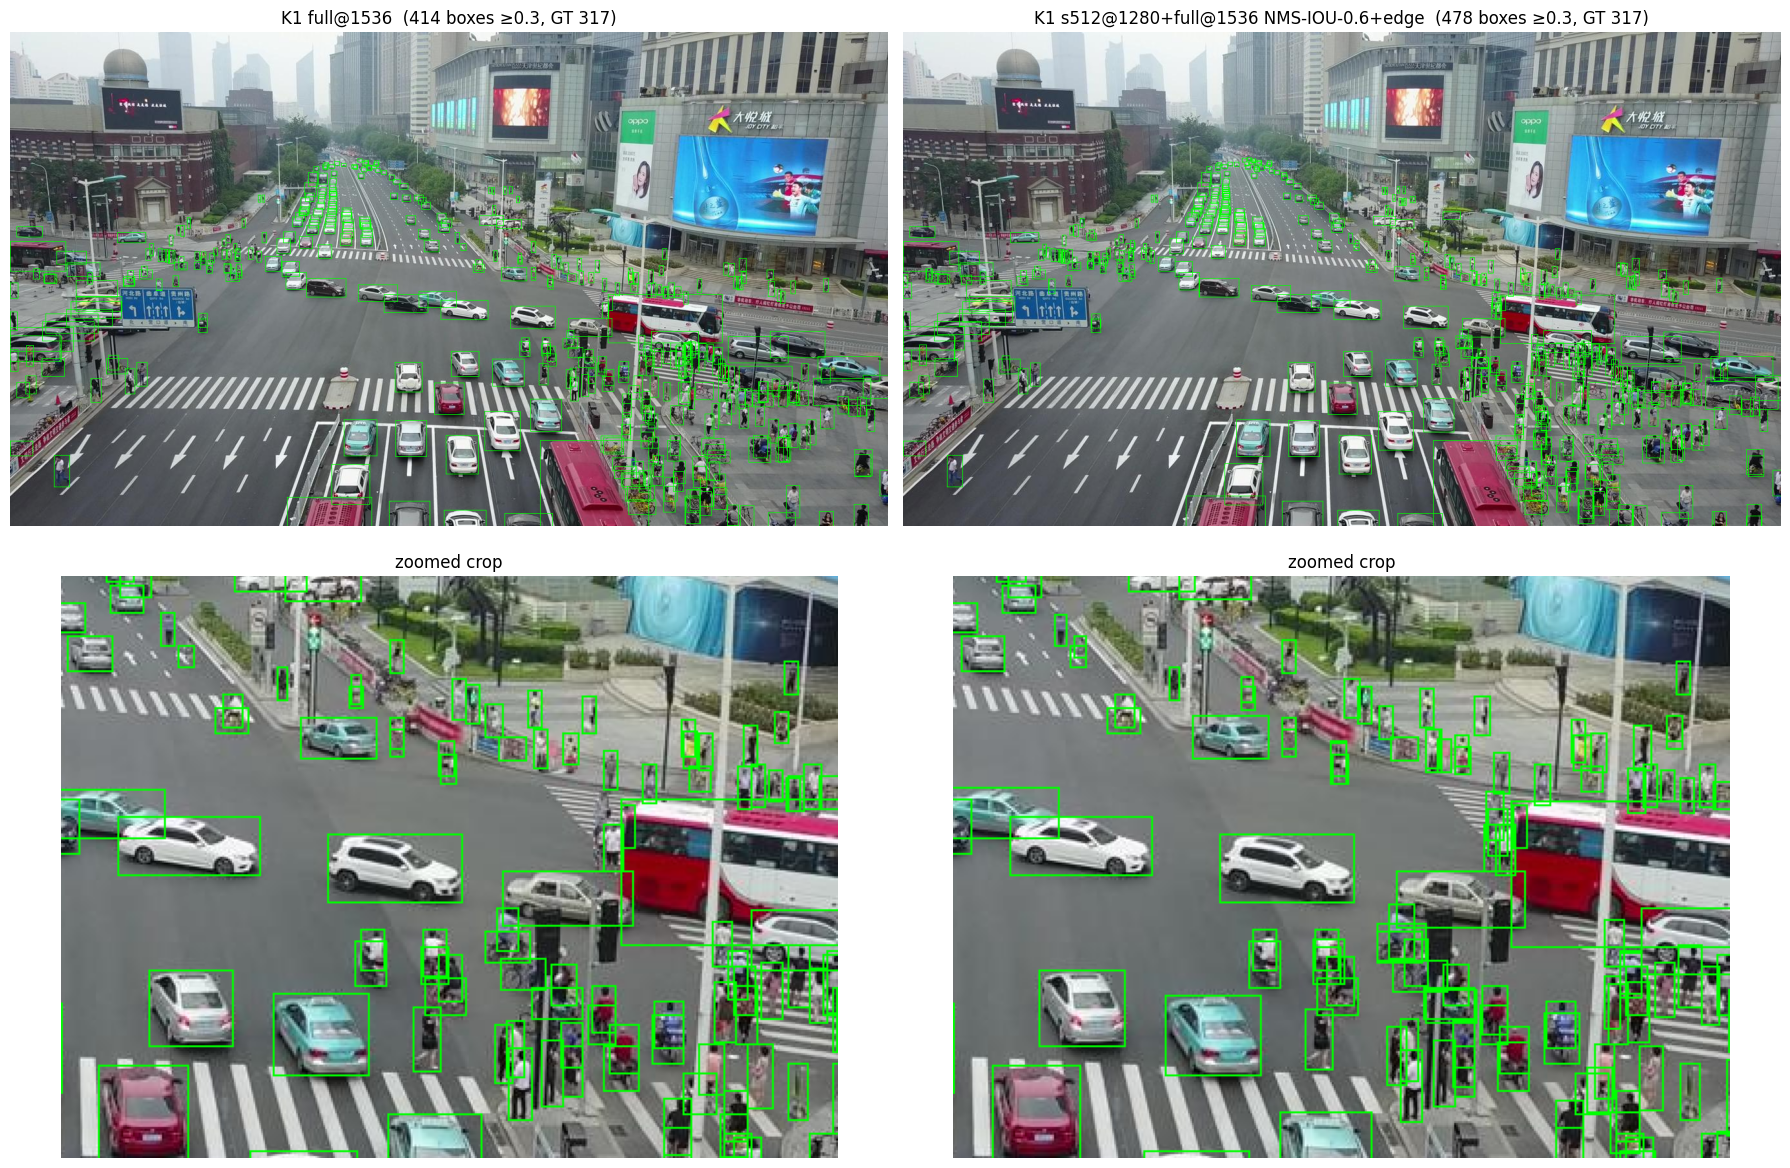

In [12]:
import matplotlib.pyplot as plt
counts = {}
for a in GT["val"]["annotations"]:
    if a["iscrowd"] == 0: counts[a["image_id"]] = counts.get(a["image_id"], 0) + 1
dense_id = max((i for i in counts if i in {im["id"] for im in image_list("val")}), key=counts.get)
im = GT["val"]["images"][dense_id]
img = cv2.imread(str(SPLIT_DIRS["val"] / "images" / im["file_name"]))
W, H = im["width"], im["height"]

def dets_for(passes, args):
    parts = []
    for k in passes:
        d, sb = run_pass("K1", "val", k)[0][dense_id]
        parts.append(edge_filter(d, sb, W, H) if args[3] else d)
    return merge(parts, *args[:3]) if len(passes) > 1 else parts[0]

def draw(d, thr=0.3):
    out = img.copy()
    for x1, y1, x2, y2, s, c in d[d[:, 4] >= thr]:
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 1)
    return out[:, :, ::-1]

full = run_pass("K1", "val", "full@1536")[0][dense_id][0]
best = dets_for(BEST_PASSES, BEST_ARGS)
fig, ax = plt.subplots(2, 2, figsize=(18, 12))
for j, (d, t) in enumerate([(full, "K1 full@1536"), (best, f"K1 {'+'.join(BEST_PASSES)} {BEST_MERGE}")]):
    ax[0, j].imshow(draw(d)); ax[0, j].set_title(f"{t}  ({(d[:,4]>=0.3).sum()} boxes ≥0.3, GT {counts[dense_id]})")
    gx = [a["bbox"] for a in GT["val"]["annotations"] if a["image_id"] == dense_id and a["iscrowd"] == 0]
    cx = int(np.median([b[0] + b[2] / 2 for b in gx])); cy = int(np.median([b[1] + b[3] / 2 for b in gx]))
    x0, y0 = max(0, cx - 200), max(0, cy - 150)
    ax[1, j].imshow(draw(d)[y0:y0 + 300, x0:x0 + 400]); ax[1, j].set_title("zoomed crop")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(EVAL / "visual_dense.png", dpi=110); plt.show()

## T — test-dev (finalists only, run once)

Finalists are fixed by the val results above: K1 full@1536, K1 best SAHI, E2 best SAHI, and the best ensemble.

In [13]:
if RUN_TESTDEV:
    evaluate("K1 full@1536 [test-dev]", "K1", "test-dev", ["full@1536"])
    evaluate("K1 v1 reference [test-dev]", "K1", "test-dev", ["s512@1024", "full@1024"], "NMS", "IOU", 0.5)
    evaluate(f"K1 best SAHI [test-dev]", "K1", "test-dev", BEST_PASSES, *BEST_ARGS)
    if MODELS["E2"] is not None:
        evaluate(f"E2 best SAHI [test-dev]", "E2", "test-dev", BEST_PASSES, *BEST_ARGS)
        dfv = pd.DataFrame(RESULTS); ens = dfv[(dfv.model == "K1+E2") & (dfv.split == "val")]
        if len(ens):
            b = ens.sort_values("AP50", ascending=False).iloc[0]
            fuse, thr = b.merge.split(" then ")[1].split("-")
            ensemble(f"K1+E2 ({b['name'].split(', ')[-1]}) [test-dev]", "test-dev", b.passes.split("+"), fuse, float(thr))
pd.DataFrame(RESULTS).query("split == 'test-dev'")[cols + ["merge"]]

  pass K1 test-dev full@1536: 39 ms/img
K1 full@1536 [test-dev]                              AP50=0.5031 AP=0.3052 AP_tiny=0.1234  39 ms
  pass K1 test-dev s512@1024: 281 ms/img
  pass K1 test-dev full@1024: 18 ms/img
K1 v1 reference [test-dev]                           AP50=0.5206 AP=0.3086 AP_tiny=0.1342  302 ms
  pass K1 test-dev s512@1280: 455 ms/img
K1 best SAHI [test-dev]                              AP50=0.5404 AP=0.3261 AP_tiny=0.1489  498 ms
  pass E2 test-dev s512@1280: 457 ms/img
  pass E2 test-dev full@1536: 36 ms/img
E2 best SAHI [test-dev]                              AP50=0.5249 AP=0.3157 AP_tiny=0.1411  497 ms
  (part) K1 s512@1280+full@1536                      AP50=0.5404 AP=0.3261 AP_tiny=0.1489  498 ms
  (part) E2 s512@1280+full@1536                      AP50=0.5249 AP=0.3157 AP_tiny=0.1411  497 ms


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.7395833042689732, 0.014523121306133754, 0.7395833042689732, 0.02080924861927323].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.8020833042689732, 0.012319363918401263, 0.8020833042689732, 0.01867774537372105].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.7369791085379465, 0.14537572134569818, 0.7369791085379465, 0.15317918806511738].
  warnings.warn("Zero area box skipped: {}.".format(box_part))


K1+E2 (WBF-0.65) [test-dev]                          AP50=0.5549 AP=0.3378 AP_tiny=0.1569  ~995 ms


,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img,merge
37,K1 full@1536 [test-dev],0.5031,0.3052,0.2923,0.4899,0.6482,39,NMS-IOU-0.5
38,K1 v1 reference [test-dev],0.5206,0.3086,0.3170,0.5059,0.6632,302,NMS-IOU-0.5
39,K1 best SAHI [test-dev],0.5404,0.3261,0.3450,0.5257,0.6730,498,NMS-IOU-0.6+edge
40,E2 best SAHI [test-dev],0.5249,0.3157,0.3341,0.5120,0.6557,497,NMS-IOU-0.6+edge
41,K1+E2 (WBF-0.65) [test-dev],0.5549,0.3378,0.3612,0.5437,0.6860,995,NMS-IOU-0.6+edge then WBF-0.65


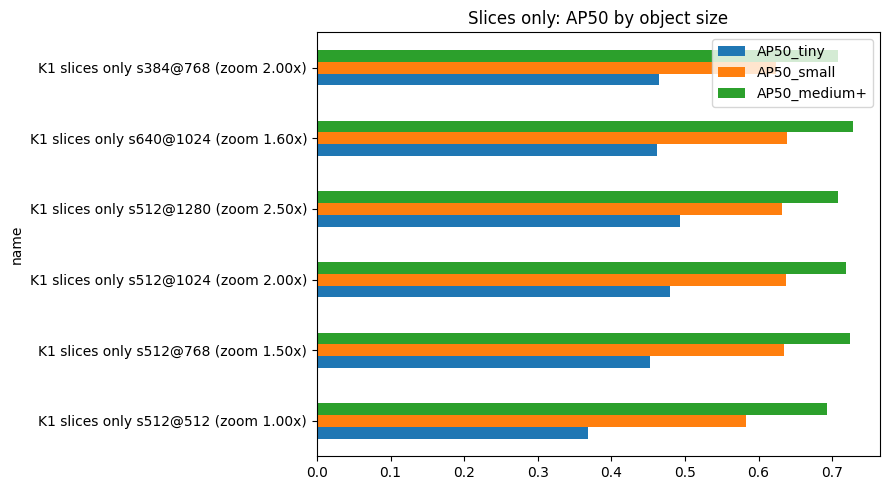

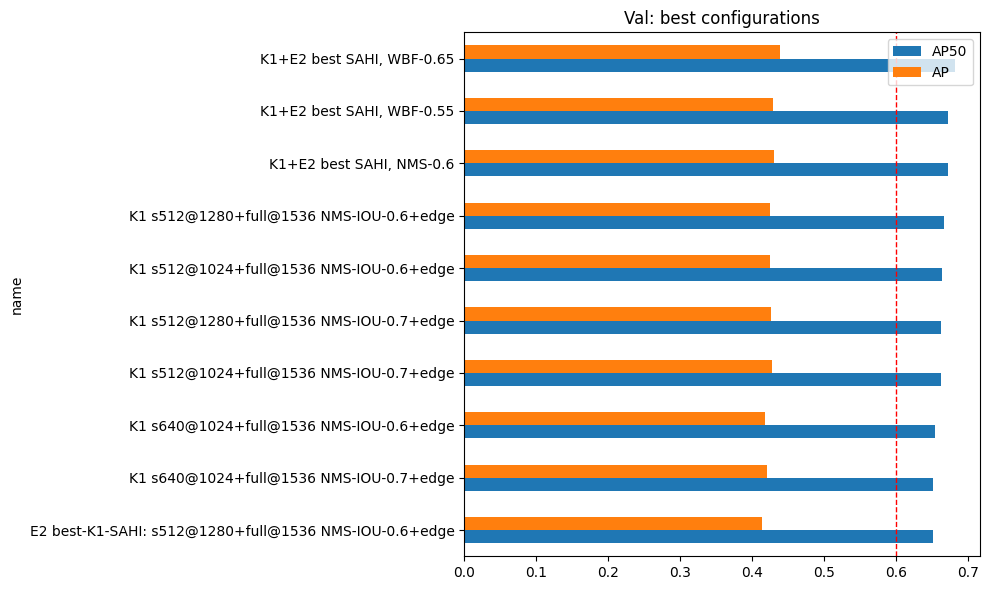

Saved:
  chart_finalists.png
  chart_zoom.png
  per_class_v2.csv
  results_v2.csv
  visual_dense.png


,name,AP50,AP,AP50_tiny,AP50_small,AP50_medium+,ms_per_img,merge,split
35,"K1+E2 best SAHI, WBF-0.65",0.6825,0.4383,0.5383,0.6912,0.7663,839,NMS-IOU-0.6+edge then WBF-0.65,val
34,"K1+E2 best SAHI, WBF-0.55",0.6724,0.4293,0.5246,0.6790,0.7586,839,NMS-IOU-0.6+edge then WBF-0.55,val
36,"K1+E2 best SAHI, NMS-0.6",0.6723,0.4298,0.5298,0.6802,0.7593,839,NMS-IOU-0.6+edge then NMS-0.6,val
19,K1 s512@1280+full@1536 NMS-IOU-0.6+edge,0.6669,0.4251,0.5226,0.6748,0.7532,426,NMS-IOU-0.6+edge,val
13,K1 s512@1024+full@1536 NMS-IOU-0.6+edge,0.6644,0.4254,0.5026,0.6759,0.7537,278,NMS-IOU-0.6+edge,val
20,K1 s512@1280+full@1536 NMS-IOU-0.7+edge,0.6631,0.4267,0.5179,0.6713,0.7503,427,NMS-IOU-0.7+edge,val
14,K1 s512@1024+full@1536 NMS-IOU-0.7+edge,0.6624,0.4273,0.4997,0.6734,0.7530,278,NMS-IOU-0.7+edge,val
25,K1 s640@1024+full@1536 NMS-IOU-0.6+edge,0.6546,0.4186,0.4791,0.6646,0.7513,196,NMS-IOU-0.6+edge,val
26,K1 s640@1024+full@1536 NMS-IOU-0.7+edge,0.6518,0.4201,0.4747,0.6620,0.7497,196,NMS-IOU-0.7+edge,val
29,E2 best-K1-SAHI: s512@1280+full@1536 NMS-IOU-0...,0.6508,0.4139,0.4997,0.6587,0.7394,412,NMS-IOU-0.6+edge,val


In [14]:
# --- Summary, per-class table, charts, files --------------------------------
df = pd.DataFrame(RESULTS)
df.to_csv(EVAL / "results_v2.csv", index=False)
pd.DataFrame(PER_CLASS).T.to_csv(EVAL / "per_class_v2.csv")

# Chart 1: zoom vs AP by object size (slices only)
z = df[df.name.str.contains("slices only")].copy()
z["zoom"] = z.name.str.extract(r"zoom ([\d.]+)x").astype(float)
ax = z.set_index("name")[["AP50_tiny", "AP50_small", "AP50_medium+"]].plot.barh(figsize=(9, 5), title="Slices only: AP50 by object size")
plt.tight_layout(); plt.savefig(EVAL / "chart_zoom.png", dpi=140); plt.show()

# Chart 2: finalists on val
fin = df[(df.split == "val") & ~df.name.str.contains("slices only")].sort_values("AP50").tail(10)
ax = fin.set_index("name")[["AP50", "AP"]].plot.barh(figsize=(10, 6), title="Val: best configurations")
ax.axvline(0.60, ls="--", c="r", lw=1); plt.tight_layout(); plt.savefig(EVAL / "chart_finalists.png", dpi=140); plt.show()

print("Saved:", *sorted(p.name for p in EVAL.glob("*.*")), sep="\n  ")
df[cols + ["merge", "split"]].sort_values(["split", "AP50"], ascending=[False, False])